# FarmTech Solutions: detecção de vacas e cachorros com YOLOv5

**FIAP · Fase 6 · Entrega 1** · Dupla: Guilherme Ávila (RM XXXXX) e Kainan (RM XXXXX)

A FarmTech Solutions expandiu seus serviços de IA para saúde animal e segurança de propriedades rurais. Este notebook mostra a um cliente, na prática, como um sistema de visão computacional aprende a **localizar e diferenciar vacas e cachorros** numa imagem, e com que acurácia.

Usamos o **YOLOv5** com *transfer learning*: partimos de uma rede já treinada no dataset COCO e ajustamos as camadas finais às nossas duas classes. Treinamos duas vezes, com **30 e 60 épocas**, e comparamos acurácia, erro e desempenho.

**Roteiro**

1. O problema e o dataset
2. Configuração do ambiente
3. Conferência visual dos rótulos
4. Treinamento (30 e 60 épocas)
5. Curvas de treinamento
6. Validação
7. Teste e imagens processadas
8. Comparação 30 × 60 épocas
9. Conclusões
10. Salvar resultados no Google Drive

## 1. O problema e o dataset

**Por que vaca e cachorro.** São dois animais presentes no dia a dia de uma fazenda, ligados ao novo serviço de saúde animal da FarmTech. Os dois são quadrúpedes, o que torna a separação menos trivial do que entre objetos sem relação; há casos realmente parecidos, como o dálmata e a vaca holandesa, ambos malhados de preto e branco. As duas classes também existem no COCO, o que permite comparar este modelo com o YOLO pré-treinado na Entrega 2.

**De onde vieram as imagens.** São 80 fotos do Flickr com licença CC0, domínio público, CC BY ou CC BY-SA, buscadas pela API do Openverse. Como o COCO também foi montado com fotos do Flickr, descartamos automaticamente qualquer foto cujo ID constasse no COCO train2017 + val2017 (123.287 IDs). Assim, nenhuma imagem do nosso teste foi vista pelo YOLO pré-treinado. Autor, licença e link de cada foto estão no arquivo `fontes.csv` do dataset.

**Curadoria.** De 120 candidatas (60 por classe), descartamos ilustrações, brinquedos, fotos sem o animal, duplicatas e fotos com as duas classes juntas, e cortamos excessos para manter variedade de raças, cenários, distâncias e número de animais.

**Divisão.** Por classe: 32 imagens de treino, 4 de validação e 4 de teste. A divisão é sorteada com semente fixa, com uma exceção deliberada: em cada classe, 2 fotos difíceis foram fixadas no teste (a vaca malhada como dálmata, o zebu na névoa, o dálmata e o labrador preto no pasto).

**Rotulação.** As caixas foram rotuladas no formato YOLO e revisadas no Make Sense: 169 caixas, 120 de vaca e 49 de cachorro, contando todos os animais reconhecíveis de cada foto. Animais muito pequenos (menos de ~15 px) ou quase totalmente escondidos não foram rotulados.

## 2. Configuração do ambiente

Recomendamos executar no Google Colab com GPU (*Ambiente de execução → Alterar o tipo de ambiente de execução → GPU T4*). O notebook detecta o dispositivo sozinho: GPU NVIDIA no Colab, GPU integrada (MPS) num Mac com Apple Silicon, ou CPU.

A célula abaixo concentra todos os parâmetros. **Só os parâmetros de épocas mudam entre os dois treinos**; tamanho de imagem, lote, pesos iniciais e semente são os mesmos, para que a comparação seja justa.

In [1]:
import json, os, shutil, sys, time  # utilitários da biblioteca padrão
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")  # no Mac (MPS), operações sem suporte na GPU caem para a CPU em vez de dar erro
os.environ["WANDB_MODE"] = "disabled"  # desliga o Weights & Biases: no Colab ele trava cada treino por 30 s pedindo login
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # silencia avisos do TensorFlow (instalado no Colab, mas não usado aqui)
from pathlib import Path  # manipulação de caminhos

IN_COLAB = "google.colab" in sys.modules  # True quando o notebook roda no Google Colab
START_DIR = Path.cwd()  # pasta onde o notebook foi aberto (para voltar a ela depois de rodar o YOLOv5)
BASE = Path("/content") if IN_COLAB else Path.cwd() / "content"  # pasta de trabalho (no Colab, /content)
BASE.mkdir(parents=True, exist_ok=True)  # garante que a pasta existe

REPO_URL = "https://github.com/Avila237/guilherme-kainan-fiap-fase6.git"  # repositório público da entrega, que contém o dataset
DATASET_SUBDIR = "dataset"  # pasta do dataset dentro do repositório
YOLOV5_COMMIT = "f9578796b8a64889aa9e66dc06914d19f40d338e"  # versão fixa do YOLOv5 (06/10/2026), para o resultado ser reproduzível

IMG_SIZE = 640  # lado da imagem de entrada da rede, em pixels
BATCH = 16  # imagens por lote de treino
WEIGHTS = "yolov5s.pt"  # pesos iniciais: YOLOv5 small pré-treinado no COCO (transfer learning)
SEED = 0  # semente aleatória, igual nos dois treinos
RUNS = {"e30": 30, "e60": 60}  # nome do experimento -> número de épocas

YOLO_DIR = BASE / "yolov5"  # onde o YOLOv5 será clonado
DATASET_DIR = BASE / "dataset"  # onde o dataset ficará no ambiente
TIMES_FILE = BASE / "tempos_treino.json"  # tempos de treino, salvos para sobreviver a reexecuções de células
print(f"Colab: {IN_COLAB} | pasta de trabalho: {BASE}")  # confirma o ambiente detectado

Colab: True | pasta de trabalho: /content


In [2]:
import torch  # PyTorch, usado pelo YOLOv5

if torch.cuda.is_available():  # GPU NVIDIA (ex.: T4 do Colab)
    DEVICE = "0"  # primeira GPU CUDA
    print("GPU:", torch.cuda.get_device_name(0))  # mostra o modelo da GPU
elif torch.backends.mps.is_available():  # GPU integrada do Mac com Apple Silicon
    DEVICE = "mps"  # o YOLOv5 só usa o MPS quando pedido explicitamente
    print("GPU Apple (MPS)")  # confirma o dispositivo
else:
    DEVICE = "cpu"  # sem GPU
    print("ATENÇÃO: sem GPU. O treino vai funcionar, mas pode levar horas na CPU.")  # avisa em vez de falhar

GPU: Tesla T4


### 2.1 YOLOv5

Clonamos o repositório oficial do YOLOv5 e fixamos o commit, para que futuras mudanças no projeto não alterem o resultado. No Colab, as dependências são instaladas a partir do `requirements.txt` do próprio YOLOv5; fora do Colab, instale-as no seu ambiente antes.

In [3]:
if not YOLO_DIR.exists():  # clona só na primeira execução
    !git clone -q https://github.com/ultralytics/yolov5 "{YOLO_DIR}"
!git -C "{YOLO_DIR}" checkout -q {YOLOV5_COMMIT}
if IN_COLAB:  # no Colab, instala as dependências do YOLOv5
    !"{sys.executable}" -m pip install -q -r "{YOLO_DIR}/requirements.txt"
!git -C "{YOLO_DIR}" log -1 --format="YOLOv5 no commit %h de %cd"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 37.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 9.6 MB/s eta 0:00:00
YOLOv5 no commit f9578796 de Tue Oct 6 19:48:38 2026 +0200


### 2.2 Dataset

O dataset é baixado do repositório público da entrega, para que qualquer pessoa consiga executar o notebook (inclusive sem acesso ao nosso Google Drive). Uma cópia idêntica, organizada nas mesmas pastas, está no Drive do grupo. A estrutura segue o padrão do YOLO: `images/{train,val,test}` e `labels/{train,val,test}`, com um `.txt` por imagem.

In [4]:
import yaml  # leitura e escrita do data.yaml

repo_dir = BASE / "entrega"  # cópia local do repositório da entrega
if not repo_dir.exists():  # clona só na primeira execução
    !git clone -q --depth 1 {REPO_URL} "{repo_dir}"
src = repo_dir / DATASET_SUBDIR  # pasta do dataset dentro do repositório
if not (src / "data.yaml").is_file():  # falha cedo e com mensagem clara se o repositório não tiver o dataset
    raise FileNotFoundError(f"data.yaml não encontrado em {src}. Confira REPO_URL e DATASET_SUBDIR.")
shutil.copytree(src, DATASET_DIR, dirs_exist_ok=True)  # copia o dataset para a pasta de trabalho

data_cfg = yaml.safe_load((DATASET_DIR / "data.yaml").read_text())  # lê a configuração do dataset
data_cfg["path"] = str(DATASET_DIR)  # aponta para a cópia local, onde quer que o notebook rode
DATA_YAML = DATASET_DIR / "data.yaml"  # caminho que será passado ao YOLOv5
DATA_YAML.write_text(yaml.safe_dump(data_cfg, sort_keys=False))  # grava a configuração ajustada
CLASSES = data_cfg["names"]  # nomes das classes, na ordem dos IDs (0 = cow, 1 = dog)
print(data_cfg)  # mostra a configuração final

{'path': '/content/dataset', 'train': 'images/train', 'val': 'images/val', 'test': 'images/test', 'nc': 2, 'names': ['cow', 'dog']}


In [5]:
import pandas as pd  # tabelas

rows = []  # uma linha por divisão do dataset
for split in ("train", "val", "test"):  # percorre treino, validação e teste
    images = sorted((DATASET_DIR / "images" / split).glob("*.jpg"))  # imagens da divisão
    boxes = {c: 0 for c in CLASSES}  # contador de caixas por classe
    for img in images:  # para cada imagem, lê o rótulo correspondente
        label = DATASET_DIR / "labels" / split / f"{img.stem}.txt"  # mesmo nome, extensão .txt
        if not label.is_file():  # toda imagem precisa de rótulo
            raise FileNotFoundError(f"rótulo ausente: {label}")
        for line in label.read_text().split("\n"):  # uma caixa por linha
            if line.strip():  # ignora linhas vazias
                boxes[CLASSES[int(line.split()[0])]] += 1  # o primeiro número é o ID da classe
    rows.append({"divisão": split, "imagens": len(images),
                 **{f"imagens {c}": sum(i.name.startswith(c) for i in images) for c in CLASSES},
                 **{f"caixas {c}": n for c, n in boxes.items()}})  # monta a linha da tabela
resumo = pd.DataFrame(rows).set_index("divisão")  # tabela final
expected = {"train": 32, "val": 4, "test": 4}  # divisão exigida pelo enunciado, por classe
for split, n in expected.items():  # confere a divisão antes de treinar
    for c in CLASSES:
        assert resumo.loc[split, f"imagens {c}"] == n, f"{split}/{c}: esperado {n}"
resumo  # exibe a tabela

,imagens,imagens cow,imagens dog,caixas cow,caixas dog
divisão,,,,,
train,64,32,32,108,39
val,8,4,4,6,4
test,8,4,4,5,6


## 3. Conferência visual dos rótulos

Antes de treinar, desenhamos as caixas de algumas imagens de treino para confirmar que os rótulos estão na posição e na classe certas. Um rótulo trocado aqui ensinaria a rede errado sem nenhuma mensagem de erro.

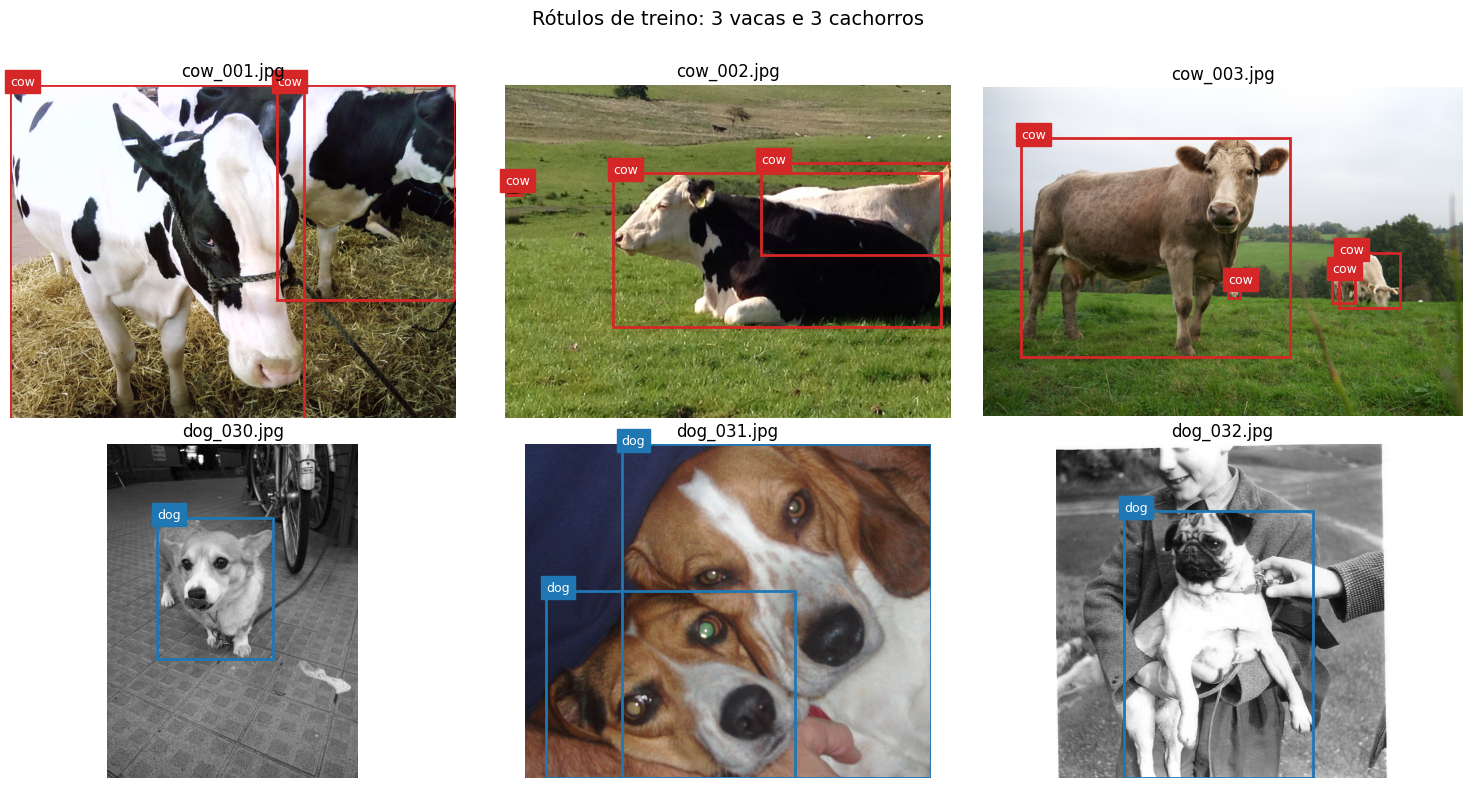

In [6]:
import matplotlib.pyplot as plt  # gráficos
import matplotlib.patches as patches  # retângulos sobre a imagem
from PIL import Image  # leitura de imagens

COLORS = {"cow": "tab:red", "dog": "tab:blue"}  # cor da caixa por classe


def show_labels(image_paths, split, title):
    # Desenha as caixas rotuladas sobre cada imagem
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))  # grade 2 x 3
    for ax, img_path in zip(axes.flat, image_paths):  # uma imagem por quadro
        img = Image.open(img_path)  # abre a imagem
        w, h = img.size  # dimensões para converter coordenadas normalizadas em pixels
        ax.imshow(img)  # mostra a imagem
        label = DATASET_DIR / "labels" / split / f"{img_path.stem}.txt"  # rótulo correspondente
        for line in label.read_text().split("\n"):  # uma caixa por linha
            if not line.strip():  # ignora linhas vazias
                continue
            cls, xc, yc, bw, bh = line.split()  # formato YOLO: classe, centro x, centro y, largura, altura
            name = CLASSES[int(cls)]  # nome da classe
            x0, y0 = (float(xc) - float(bw) / 2) * w, (float(yc) - float(bh) / 2) * h  # canto superior esquerdo em pixels
            ax.add_patch(patches.Rectangle((x0, y0), float(bw) * w, float(bh) * h, fill=False, lw=2, color=COLORS[name]))  # caixa
            ax.text(x0, y0, name, color="white", backgroundcolor=COLORS[name], fontsize=9)  # nome da classe
        ax.set_title(img_path.name)  # nome do arquivo
        ax.axis("off")  # sem eixos
    fig.suptitle(title, fontsize=14)  # título geral
    plt.tight_layout(rect=(0, 0, 1, 0.96))  # ajusta espaçamentos, reservando o topo para o título geral
    plt.show()  # exibe


train_imgs = sorted((DATASET_DIR / "images" / "train").glob("*.jpg"))  # imagens de treino
show_labels(train_imgs[:3] + train_imgs[-3:], "train", "Rótulos de treino: 3 vacas e 3 cachorros")  # amostra das duas classes

## 4. Treinamento

Treinamos o YOLOv5s duas vezes, mudando só o número de épocas (uma época é uma passada completa por todas as imagens de treino):

| Experimento | Épocas | Pasta de resultados |
|---|---|---|
| `e30` | 30 | `yolov5/runs/train/e30` |
| `e60` | 60 | `yolov5/runs/train/e60` |

Os resultados ficam em pastas com nome fixo, em vez de `exp`, `exp2`, `exp3`…, para que reexecutar o notebook sobrescreva o mesmo experimento em vez de criar pastas novas. Ao fim de cada época, o YOLOv5 avalia o modelo na validação e guarda dois pesos: `last.pt` (última época) e `best.pt` (época com melhor *fitness*, uma combinação de 10% do mAP@0.5 e 90% do mAP@0.5:0.95).

In [7]:
def load_times():
    # Lê os tempos de treino já registrados (permite reexecutar células sem perder o histórico)
    return json.loads(TIMES_FILE.read_text()) if TIMES_FILE.is_file() else {}


def train(name, epochs):
    # Treina um experimento, mede o tempo total e confere que os resultados foram gerados
    start = time.perf_counter()  # marca o início
    os.chdir(YOLO_DIR)  # o YOLOv5 espera ser executado de dentro da própria pasta
    try:
        !"{sys.executable}" train.py --img {IMG_SIZE} --batch {BATCH} --epochs {epochs} --data "{DATA_YAML}" --weights {WEIGHTS} --seed {SEED} --device {DEVICE} --name {name} --exist-ok
    finally:
        os.chdir(START_DIR)  # volta para a pasta original, mesmo se o treino falhar
    elapsed = time.perf_counter() - start  # duração em segundos
    results = YOLO_DIR / "runs" / "train" / name / "results.csv"  # métricas por época gravadas pelo YOLOv5
    if not results.is_file():  # o comando '!' não interrompe o notebook em caso de erro; checamos o resultado
        raise RuntimeError(f"Treino {name} falhou: {results} não foi gerado. Veja o log acima.")
    times = load_times()  # tempos anteriores
    times[name] = elapsed  # registra este treino
    TIMES_FILE.write_text(json.dumps(times))  # persiste em disco
    print(f"{name}: {epochs} épocas em {elapsed / 60:.1f} min")  # resumo

In [8]:
train("e30", RUNS["e30"])  # treino com 30 épocas

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791905323.687931     792 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
train: weights=yolov5s.pt, cfg=, data=/content/dataset/data.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=30, batch_size=16, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=None, image_weights=False, device=0, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, pro

In [9]:
train("e60", RUNS["e60"])  # treino com 60 épocas

WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791905445.949308    1435 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
train: weights=yolov5s.pt, cfg=, data=/content/dataset/data.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=60, batch_size=16, imgsz=640, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=None, image_weights=False, device=0, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, project=runs/train, name=e60, exist_ok=True, quad=False, cos_lr=False, label_smoothing=0.0, patience=100, freeze=[0], save_period=-1, seed=0, local_rank=-1, entity=None, upload_dataset=False, bbox_interval=-1
github: up to date with https://github.com/ultralytics/yolov5 ✅
YOLOv5 🚀 v7.0-556-gf957

## 5. Curvas de treinamento: 30 × 60 épocas

O YOLOv5 registra, a cada época, três perdas (erros) e quatro métricas de acurácia:

- **box_loss**: erro na posição e no tamanho das caixas.
- **obj_loss**: erro em decidir se há ou não um objeto numa região.
- **cls_loss**: erro em decidir a classe (vaca ou cachorro).
- **precision**: das caixas que o modelo previu, quantas estavam certas.
- **recall**: dos animais rotulados, quantos o modelo encontrou.
- **mAP@0.5**: precisão média considerando certa a caixa que se sobrepõe pelo menos 50% (IoU ≥ 0,5) à caixa rotulada.
- **mAP@0.5:0.95**: a mesma média, exigindo sobreposições de 50% a 95%; mede também a justeza das caixas.

As perdas de treino (`train/`) caem enquanto a rede aprende. As de validação (`val/`) mostram se ela generaliza: quando a perda de validação para de cair, ou sobe, enquanto a de treino continua caindo, há sinal de *overfitting*.

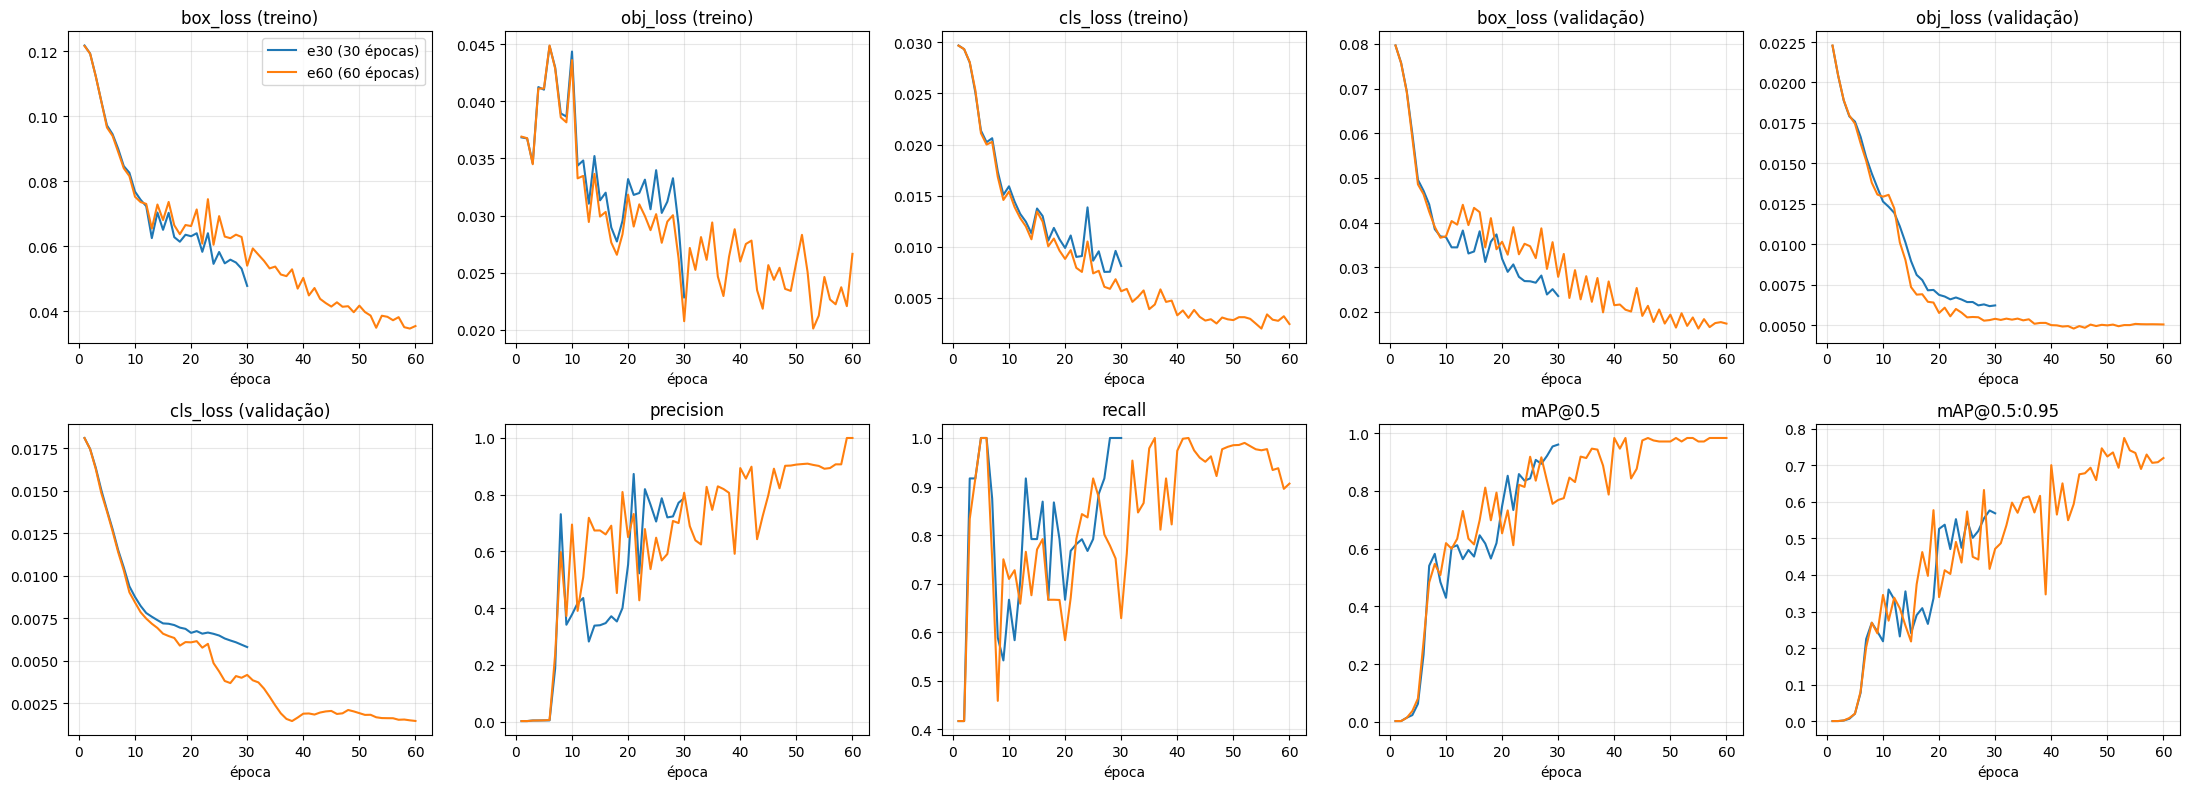

In [10]:
def load_results(name):
    # Lê o results.csv de um experimento e limpa os espaços nos nomes das colunas
    df = pd.read_csv(YOLO_DIR / "runs" / "train" / name / "results.csv")  # métricas por época
    df.columns = [c.strip() for c in df.columns]  # o YOLOv5 grava os cabeçalhos com espaços
    return df


history = {name: load_results(name) for name in RUNS}  # histórico dos dois treinos
panels = [  # (coluna do results.csv, título do gráfico)
    ("train/box_loss", "box_loss (treino)"), ("train/obj_loss", "obj_loss (treino)"), ("train/cls_loss", "cls_loss (treino)"),
    ("val/box_loss", "box_loss (validação)"), ("val/obj_loss", "obj_loss (validação)"), ("val/cls_loss", "cls_loss (validação)"),
    ("metrics/precision", "precision"), ("metrics/recall", "recall"),
    ("metrics/mAP_0.5", "mAP@0.5"), ("metrics/mAP_0.5:0.95", "mAP@0.5:0.95"),
]
fig, axes = plt.subplots(2, 5, figsize=(22, 8))  # grade 2 x 5
for ax, (col, title) in zip(axes.flat, panels):  # um gráfico por métrica
    for name, df in history.items():  # as duas curvas no mesmo gráfico
        ax.plot(df["epoch"] + 1, df[col], label=f"{name} ({RUNS[name]} épocas)")  # época começa em 0 no CSV
    ax.set_title(title)  # título
    ax.set_xlabel("época")  # eixo x
    ax.grid(alpha=0.3)  # grade leve
axes.flat[0].legend()  # legenda no primeiro gráfico
plt.tight_layout()  # ajusta espaçamentos
plt.show()  # exibe

In [11]:
def best_epoch(df):
    # Época escolhida pelo YOLOv5 para o best.pt: maior fitness = 0,1 * mAP@0.5 + 0,9 * mAP@0.5:0.95
    fitness = 0.1 * df["metrics/mAP_0.5"] + 0.9 * df["metrics/mAP_0.5:0.95"]  # mesma fórmula do YOLOv5
    return int(fitness.idxmax()) + 1  # +1 porque a época começa em 0 no CSV


pd.DataFrame({name: {"épocas": RUNS[name], "melhor época (best.pt)": best_epoch(df),
                     "box_loss val. final": df["val/box_loss"].iloc[-1],
                     "cls_loss val. final": df["val/cls_loss"].iloc[-1]}
              for name, df in history.items()}).T.astype({"épocas": int, "melhor época (best.pt)": int})  # resumo por experimento

,épocas,melhor época (best.pt),box_loss val. final,cls_loss val. final
e30,30,29,0.023541,0.005796
e60,60,53,0.017369,0.001447


## 6. Validação

Avaliamos o `best.pt` de cada treino nas 8 imagens de validação. Usamos a função `val.run` do próprio YOLOv5, que devolve precisão, recall e mAP; ela também grava a matriz de confusão e as curvas em `yolov5/runs/val/<experimento>_<conjunto>`.

In [12]:
if str(YOLO_DIR) not in sys.path:  # permite importar os módulos do YOLOv5
    sys.path.insert(0, str(YOLO_DIR))
import val as yolo_val  # módulo de validação do YOLOv5
%matplotlib inline
# a linha acima restaura a exibição de gráficos: ao ser importado, o YOLOv5 troca o matplotlib para o modo 'Agg' (só arquivo)


def evaluate(name, task):
    # Avalia o best.pt de um experimento no conjunto 'val' ou 'test'
    weights = YOLO_DIR / "runs" / "train" / name / "weights" / "best.pt"  # melhor peso do treino
    (mp, mr, map50, map5095, *_), maps, speed = yolo_val.run(
        data=str(DATA_YAML), weights=str(weights), imgsz=IMG_SIZE, task=task, device=DEVICE,  # dados, pesos, conjunto e dispositivo
        project=str(YOLO_DIR / "runs" / "val"), name=f"{name}_{task}", exist_ok=True,  # pasta dos gráficos
        verbose=True, plots=True)  # métricas por classe e matriz de confusão
    return {"precision": mp, "recall": mr, "mAP@0.5": map50, "mAP@0.5:0.95": map5095,  # métricas gerais
            **{f"mAP@0.5:0.95 {c}": maps[i] for i, c in enumerate(CLASSES)}}  # métrica por classe


val_metrics = pd.DataFrame({name: evaluate(name, "val") for name in RUNS}).T  # uma linha por experimento
val_metrics.round(3)  # exibe a tabela

YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
val: Scanning /content/dataset/labels/val.cache... 8 images, 0 backgrounds, 0 corrupt
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 1/1 1.2it/s 0.8s
                   all          8         10      0.773          1      0.954      0.576
                   cow          8          6       0.62          1      0.913      0.532
                   dog          8          4      0.927          1      0.995      0.621
Speed: 0.4ms pre-process, 42.8ms inference, 10.5ms NMS per image at shape (32, 3, 640, 640)
Results saved to /content/yolov5/runs/val/e30_val
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
val: Scanning /c

,precision,recall,mAP@0.5,mAP@0.5:0.95,mAP@0.5:0.95 cow,mAP@0.5:0.95 dog
e30,0.773,1.000,0.954,0.576,0.532,0.621
e60,0.905,0.983,0.984,0.774,0.714,0.833


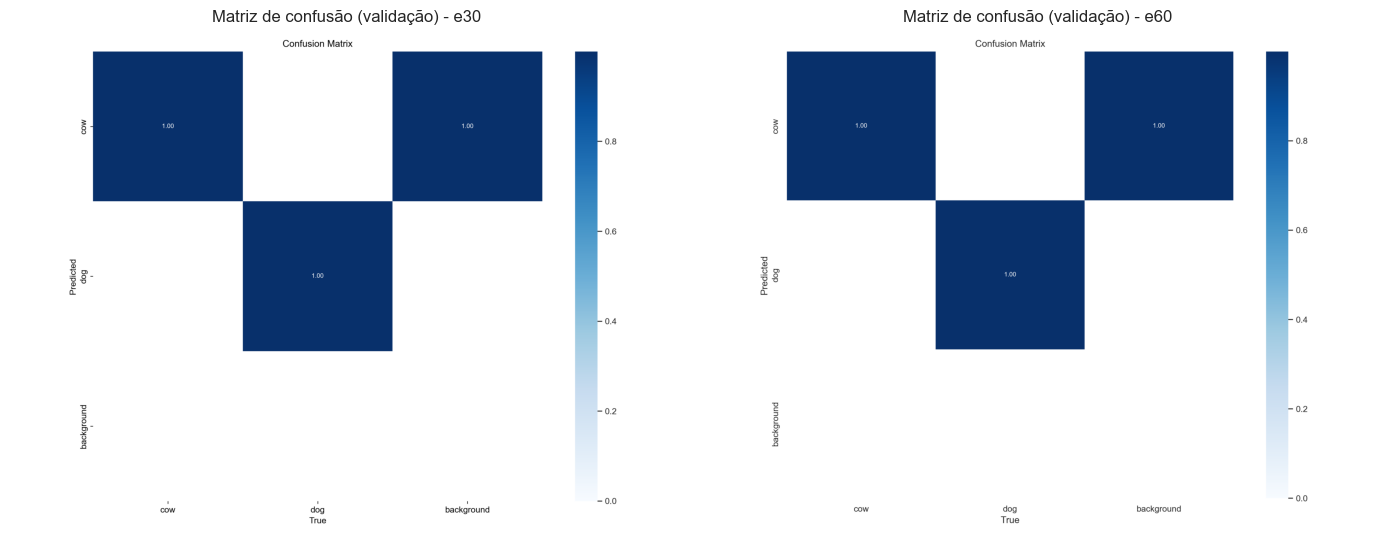

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))  # matrizes de confusão lado a lado
for ax, name in zip(axes, RUNS):  # uma por experimento
    ax.imshow(Image.open(YOLO_DIR / "runs" / "val" / f"{name}_val" / "confusion_matrix.png"))  # gravada pelo YOLOv5
    ax.set_title(f"Matriz de confusão (validação) - {name}")  # título
    ax.axis("off")  # sem eixos
plt.tight_layout()  # ajusta espaçamentos
plt.show()  # exibe

## 7. Teste e imagens processadas

O conjunto de teste (8 imagens) não participou do treino nem da escolha do `best.pt`, por isso é a medida mais honesta de como o modelo se sairia com fotos novas. Ele inclui de propósito os 4 casos difíceis descritos na seção 1.

Primeiro as métricas; depois rodamos o `detect.py`, que desenha as caixas previstas sobre as imagens (limiar de confiança de 0,25) e mede o tempo de inferência processando uma imagem por vez, como seria em produção. As imagens processadas ficam em `yolov5/runs/detect/<experimento>_test`.

In [14]:
test_metrics = pd.DataFrame({name: evaluate(name, "test") for name in RUNS}).T  # métricas no teste
test_metrics.round(3)  # exibe a tabela

YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
test: Scanning /content/dataset/labels/test... 8 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 8/8 251.4it/s 0.0s
test: New cache created: /content/dataset/labels/test.cache
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 1/1 1.7it/s 0.6s
                   all          8         11       0.58      0.733      0.764      0.552
                   cow          8          5      0.402        0.8      0.743      0.517
                   dog          8          6      0.759      0.667      0.785      0.587
Speed: 1.2ms pre-process, 6.7ms inference, 5.6ms NMS per image at shape (32, 3, 640, 640)
Results saved to /content/yolov5/runs/val/e30_test
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers.

,precision,recall,mAP@0.5,mAP@0.5:0.95,mAP@0.5:0.95 cow,mAP@0.5:0.95 dog
e30,0.580,0.733,0.764,0.552,0.517,0.587
e60,0.783,0.931,0.971,0.613,0.753,0.472


In [15]:
import re  # expressões regulares, para ler o tempo no log do detect.py

CONF = 0.25  # confiança mínima para desenhar uma detecção
test_dir = DATASET_DIR / "images" / "test"  # imagens de teste
INFER_MS = {}  # tempo de inferência por imagem (ms), por modelo
for name in RUNS:  # roda a detecção com cada modelo
    weights = YOLO_DIR / "runs" / "train" / name / "weights" / "best.pt"  # melhor peso do treino
    os.chdir(YOLO_DIR)  # o YOLOv5 espera ser executado de dentro da própria pasta
    try:
        log = !"{sys.executable}" detect.py --weights "{weights}" --source "{test_dir}" --img {IMG_SIZE} --conf-thres {CONF} --device {DEVICE} --name {name}_test --exist-ok 2>&1
    finally:
        os.chdir(START_DIR)  # volta para a pasta original
    print("\n".join(log[-10:]))  # mostra o fim do log: uma linha por imagem, com o que foi detectado
    speed = [m for line in log if (m := re.search(r"Speed:.*?([\d.]+)ms inference", line))]  # linha de resumo de tempos
    if not speed:  # sem essa linha, o detect.py não terminou
        raise RuntimeError(f"detect.py ({name}) falhou. Log:\n" + "\n".join(log[-20:]))
    INFER_MS[name] = float(speed[-1].group(1))  # ms por imagem, só a rede (sem pré e pós-processamento)
    out = YOLO_DIR / "runs" / "detect" / f"{name}_test"  # pasta com as imagens processadas
    if len(list(out.glob("*.jpg"))) != len(list(test_dir.glob("*.jpg"))):  # confere que todas foram processadas
        raise RuntimeError(f"detect.py ({name}) não gerou todas as imagens em {out}")

image 1/8 /content/dataset/images/test/cow_037.jpg: 480x640 3 cows, 29.3ms
image 2/8 /content/dataset/images/test/cow_038.jpg: 416x640 1 cow, 27.7ms
image 3/8 /content/dataset/images/test/cow_039.jpg: 448x640 (no detections), 28.5ms
image 4/8 /content/dataset/images/test/cow_040.jpg: 640x448 1 cow, 1 dog, 27.4ms
image 5/8 /content/dataset/images/test/dog_037.jpg: 448x640 (no detections), 9.0ms
image 6/8 /content/dataset/images/test/dog_038.jpg: 640x608 (no detections), 27.0ms
image 7/8 /content/dataset/images/test/dog_039.jpg: 480x640 1 cow, 1 dog, 9.2ms
image 8/8 /content/dataset/images/test/dog_040.jpg: 448x640 (no detections), 8.9ms
Speed: 0.4ms pre-process, 20.9ms inference, 14.4ms NMS per image at shape (1, 3, 640, 640)
Results saved to runs/detect/e30_test
image 1/8 /content/dataset/images/test/cow_037.jpg: 480x640 2 cows, 28.6ms
image 2/8 /content/dataset/images/test/cow_038.jpg: 416x640 1 cow, 39.5ms
image 3/8 /content/dataset/images/test/cow_039.jpg: 448x640 1 cow, 29.3ms
imag

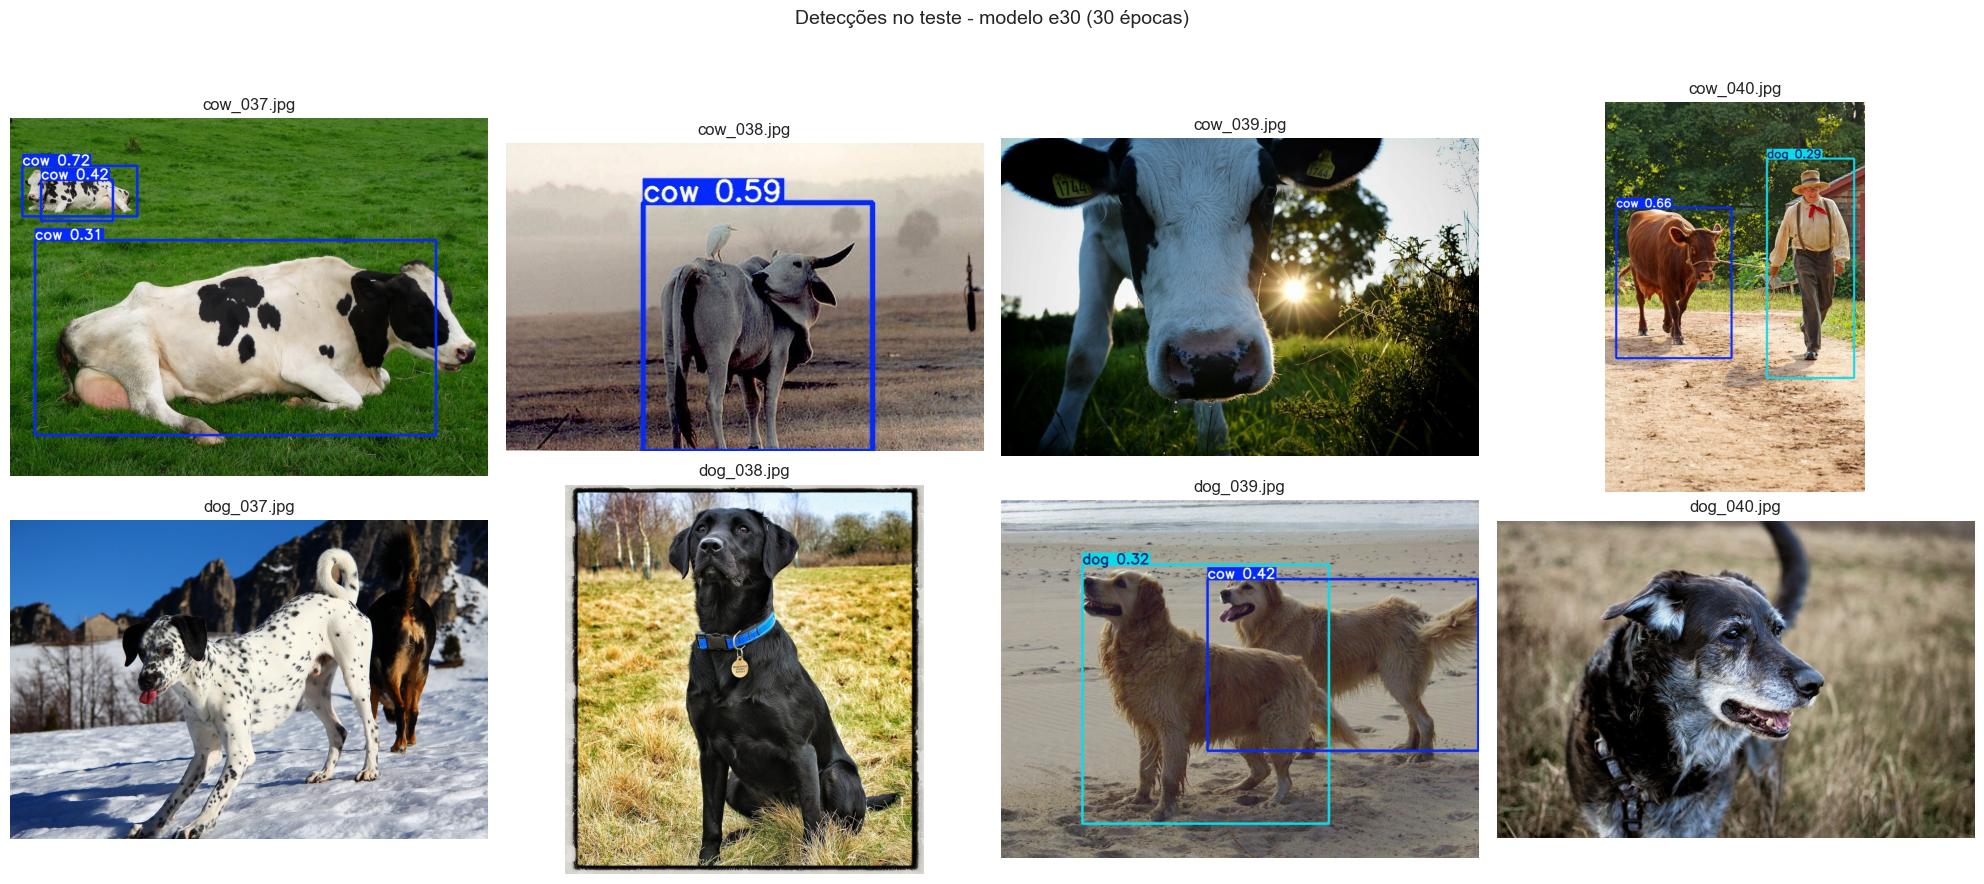

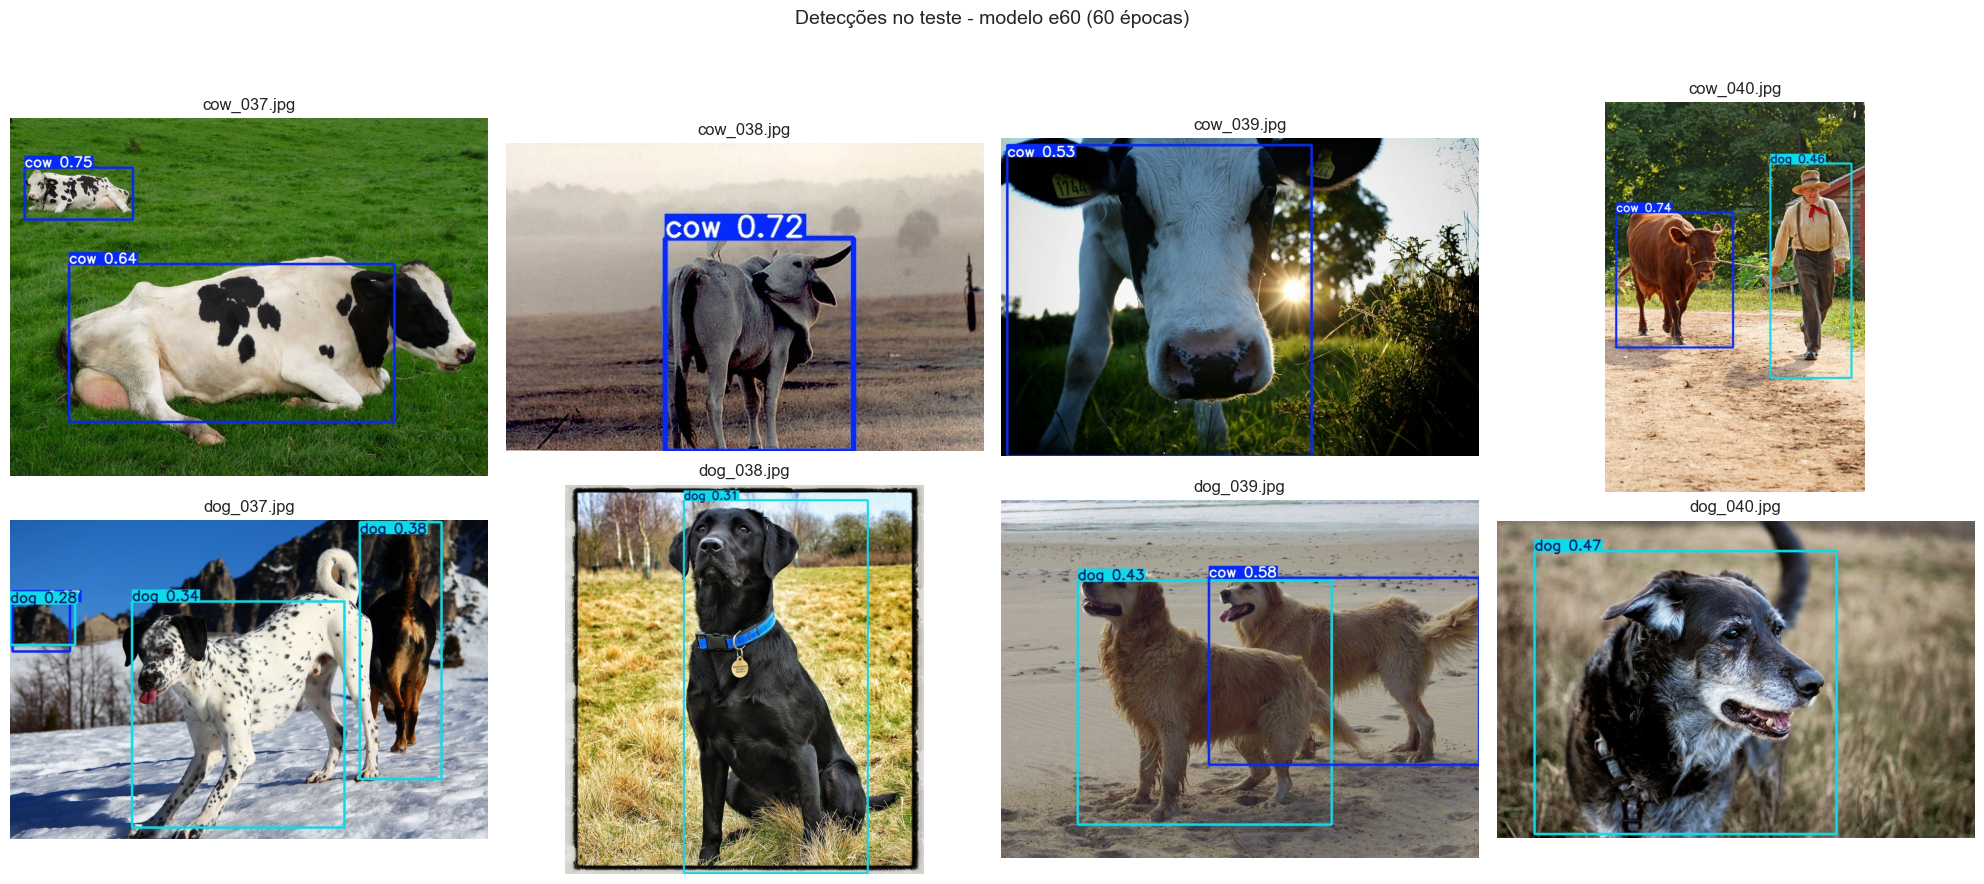

In [16]:
def show_detections(name):
    # Mostra as 8 imagens de teste com as caixas previstas pelo modelo
    out = YOLO_DIR / "runs" / "detect" / f"{name}_test"  # pasta gerada pelo detect.py
    images = sorted(out.glob("*.jpg"))  # imagens processadas
    fig, axes = plt.subplots(2, 4, figsize=(20, 9))  # grade 2 x 4
    for ax, img in zip(axes.flat, images):  # uma imagem por quadro
        ax.imshow(Image.open(img))  # imagem com as caixas desenhadas
        ax.set_title(img.name)  # nome do arquivo
        ax.axis("off")  # sem eixos
    fig.suptitle(f"Detecções no teste - modelo {name} ({RUNS[name]} épocas)", fontsize=14)  # título
    plt.tight_layout(rect=(0, 0, 1, 0.96))  # ajusta espaçamentos, reservando o topo para o título geral
    plt.show()  # exibe


for name in RUNS:  # uma grade por modelo
    show_detections(name)

## 8. Comparação 30 × 60 épocas

A tabela reúne custo (tempo de treino), acurácia (validação e teste) e desempenho (tempo de inferência por imagem) dos dois modelos.

In [17]:
times = load_times()  # tempos medidos na seção 4
comparison = pd.DataFrame({
    name: {
        "épocas": RUNS[name],
        "tempo de treino (min)": times.get(name, float("nan")) / 60,  # NaN se o tempo não foi medido nesta sessão
        "melhor época": best_epoch(history[name]),
        "mAP@0.5 validação": val_metrics.loc[name, "mAP@0.5"],
        "mAP@0.5:0.95 validação": val_metrics.loc[name, "mAP@0.5:0.95"],
        "precision teste": test_metrics.loc[name, "precision"],
        "recall teste": test_metrics.loc[name, "recall"],
        "mAP@0.5 teste": test_metrics.loc[name, "mAP@0.5"],
        "mAP@0.5:0.95 teste": test_metrics.loc[name, "mAP@0.5:0.95"],
        "inferência (ms/img)": INFER_MS[name],  # medido pelo detect.py, uma imagem por vez
    } for name in RUNS}).T.astype({"épocas": int, "melhor época": int})  # uma linha por experimento
comparison.round(3)  # exibe a tabela

,épocas,tempo de treino (min),melhor época,mAP@0.5 validação,mAP@0.5:0.95 validação,precision teste,recall teste,mAP@0.5 teste,mAP@0.5:0.95 teste,inferência (ms/img)
e30,30,2.220,29,0.954,0.576,0.580,0.733,0.764,0.552,20.9
e60,60,3.203,53,0.984,0.774,0.783,0.931,0.971,0.613,24.1


## 9. Conclusões

Resultados desta execução (Google Colab, GPU Tesla T4). Os números citados vêm das tabelas e gráficos acima.

**Resultados**

- **60 épocas foram melhores que 30 em todas as métricas de acurácia.** Na validação, o mAP@0.5:0.95 subiu de 0,576 para 0,774. No teste, o mAP@0.5 foi de 0,764 para 0,971, o mAP@0.5:0.95 de 0,552 para 0,613 e o recall de 0,733 para 0,931. Na prática: o modelo de 30 épocas não detectou nenhum animal em 4 das 8 fotos de teste (`cow_039`, `dog_037`, `dog_038`, `dog_040`); o de 60 épocas encontrou animais em todas.
- **O custo extra foi pequeno.** O treino de 60 épocas levou 3,2 min contra 2,2 min (+44%), e o tempo de inferência é praticamente o mesmo (20,9 e 24,1 ms por imagem): a arquitetura é a mesma, então essa diferença é variação de execução, não do modelo.
- **Não há sinal de *overfitting* até 60 épocas.** As perdas de validação continuaram caindo até o fim (box_loss de 0,024 para 0,017; cls_loss de 0,0058 para 0,0014) e o mAP@0.5:0.95 de validação ainda subia. A melhor época ficou perto do fim nos dois treinos (29 de 30 e 53 de 60): o treino de 30 épocas parou antes de o modelo terminar de aprender.
- **Casos difíceis do teste, no modelo de 60 épocas:**
  - `cow_038` (zebu na névoa) e `cow_039` (vaca em contraluz): detectados corretamente.
  - `dog_037` (dálmata): o dálmata e o cão tricolor foram detectados como cachorro, mas com confiança baixa (0,34 e 0,38), e houve uma detecção falsa sobre uma casa ao fundo.
  - `dog_038` (labrador preto no pasto): detectado como cachorro, com confiança baixa (0,31).
  - `dog_039` (dois golden retrievers): um foi detectado como cachorro e o outro **como vaca** (0,58).
  - `cow_040` (boi puxado por um homem): o boi foi detectado corretamente, mas **o homem foi detectado como cachorro** (0,46).
- **O modelo é mais seguro com vacas do que com cachorros.** As detecções de vaca no teste ficaram entre 0,53 e 0,75 de confiança; as de cachorro, entre 0,28 e 0,47. A causa mais provável é o desequilíbrio do dataset: o treino tem 108 caixas de vaca e só 39 de cachorro (as fotos de vaca têm, em média, mais animais).
- **Os números variam entre execuções.** Rodamos o notebook duas vezes com a mesma configuração e semente; o treino em GPU não é totalmente determinístico, e com só 8 imagens de teste qualquer variação pesa. Na outra execução, o mAP@0.5 de teste do modelo de 60 épocas foi 0,830 (aqui, 0,971). A conclusão "60 épocas > 30 épocas" se manteve nas duas; os valores exatos devem ser lidos como aproximados.

**Pontos fortes**

- *Transfer learning*: com só 64 imagens de treino, a rede parte do que já aprendeu no COCO, em vez de aprender do zero, e chega a um mAP@0.5 de 0,97 no teste em 3 minutos de treino.
- Dataset com origem e licença rastreáveis por imagem, e sem sobreposição com o COCO.
- Ambiente reproduzível: versão do YOLOv5 fixa, semente fixa, divisão do dataset determinística.

**Limitações**

- Dataset pequeno: 64 imagens de treino, 8 de validação e 8 de teste. Com 8 imagens de teste, um único erro muda bastante as métricas; os números indicam tendência, não precisão estatística.
- A validação também tem só 8 imagens e é usada para escolher o `best.pt`, o que favorece um pouco os números de validação.
- Desequilíbrio de caixas entre as classes (108 de vaca e 39 de cachorro no treino), refletido na confiança menor nas detecções de cachorro.
- Rotulação feita por uma pessoa, sem segunda revisão independente; caixas de animais pequenos ou sobrepostos em rebanhos têm margem de erro maior.
- Poucas fotos de cachorros distantes ou pequenos no quadro, e nenhuma foto com pessoas e cachorros juntos, o que ajuda a explicar a pessoa detectada como cachorro.

**Recomendação para o cliente**

- Usar o modelo de 60 épocas. Ele encontrou animais em todas as fotos de teste, com caixas bem posicionadas (mAP@0.5 de 0,97), e processa uma imagem em cerca de 39 ms numa GPU T4 contando pré-processamento, rede e pós-processamento (0,4 + 24,1 + 14,8 ms), ou seja, na ordem de 25 imagens por segundo, suficiente para monitorar câmeras em tempo real.
- Antes de usar em produção: ampliar a base com mais fotos de cachorros (principalmente malhados, escuros e distantes), incluir fotos com pessoas para o modelo aprender a não confundi-las, treinar mais de 60 épocas (as curvas ainda subiam) e validar com imagens das próprias câmeras da fazenda.


## 10. Salvar resultados no Google Drive

Opcional: copia os pesos, gráficos e imagens processadas para o Google Drive de quem executa o notebook. Pede autorização de acesso ao Drive.

In [ ]:
DRIVE_RESULTS = Path("/content/drive/MyDrive/FIAP_FASE6/resultados_entrega1")  # pasta de destino no Drive
if IN_COLAB:  # o Drive só pode ser montado no Colab
    from google.colab import drive  # integração do Colab com o Drive
    drive.mount("/content/drive")  # pede autorização e monta o Drive
    for sub in ("train", "val", "detect"):  # pastas de resultados do YOLOv5
        shutil.copytree(YOLO_DIR / "runs" / sub, DRIVE_RESULTS / sub, dirs_exist_ok=True)  # copia, sobrescrevendo
    shutil.copy2(TIMES_FILE, DRIVE_RESULTS / TIMES_FILE.name)  # tempos de treino
    print("Resultados copiados para", DRIVE_RESULTS)  # confirma
else:
    print("Fora do Colab: resultados ficam em", YOLO_DIR / "runs")  # nada a copiar